# Comparacion DenseNet121 y CNN-ViT
Primero entrenaremos una CNN de referencia y despues el CNN-ViT. Ambos usan ImageNet y las mismas particiones auditadas.

**Primer uso:** sube `nih_publication_comparison_v1.zip` a la carpeta `cxr-thesis` de Drive. Los datos NIH y sus particiones ya estan ahi. Selecciona GPU en Colab. Ejecuta hasta la tabla de validacion; no hace falta activar la evaluacion final todavia.

El entrenamiento puede tardar varias horas por modelo. `last.pt` permite recuperar la ultima epoca completa cuando Colab se desconecta. No se garantiza una mejora de metricas. El protocolo completo esta en LEEME.md dentro del ZIP.

In [1]:
%pip -q install h5py pandas scikit-learn torchxrayvision==1.4.0 matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 10.1 MB/s eta 0:00:00


In [3]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import shutil, zipfile, subprocess, sys, json
import torch
if not torch.cuda.is_available():
    raise RuntimeError('Selecciona GPU en Entorno de ejecucion > Cambiar tipo de entorno.')
print('GPU:', torch.cuda.get_device_name(0))
DRIVE_ROOT = Path('/content/drive/MyDrive/cxr-thesis')
BUNDLE = DRIVE_ROOT / 'nih_publication_comparison_v1.zip'
SOURCE_HDF5 = DRIVE_ROOT / 'nih_images_complete_20260925.h5'
SOURCE_SPLITS = DRIVE_ROOT / 'nih_splits_full_v1_20260925'
for path in (BUNDLE, SOURCE_HDF5, SOURCE_SPLITS / 'manifest.json'):
    if not path.exists():
        raise FileNotFoundError(f'No se encontro {path}')
WORKDIR = Path('/content/nih-publication-comparison-v1')
WORKDIR.mkdir(exist_ok=True)
with zipfile.ZipFile(BUNDLE) as bundle:
    if any('/' in n or '\\' in n or n in ('.', '..') for n in bundle.namelist()):
        raise ValueError('ZIP inesperado: debe contener archivos en una sola carpeta.')
    bundle.extractall(WORKDIR)
LOCAL_HDF5 = Path('/content/nih_images_complete_20260925.h5')
LOCAL_SPLITS = Path('/content/nih_splits_full_v1_20260925')
if not LOCAL_HDF5.exists():
    if shutil.disk_usage('/content').free < SOURCE_HDF5.stat().st_size + 1_000_000_000:
        raise OSError('Falta espacio temporal en Colab.')
    print('Copiando 5.6 GB de Drive; espera unos minutos...')
    shutil.copy2(SOURCE_HDF5, LOCAL_HDF5)
if not LOCAL_SPLITS.exists():
    shutil.copytree(SOURCE_SPLITS, LOCAL_SPLITS)
print('Datos listos. La siguiente celda configura el experimento.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA A100-SXM4-80GB
Copiando 5.6 GB de Drive; espera unos minutos...
Datos listos. La siguiente celda configura el experimento.


|## Configura el modelo
Deja `MODEL = 'densenet121'` para la primera ejecucion. Cuando termine, cambia solamente MODEL a `'cnn_vit'` y vuelve a ejecutar desde esta celda hasta la tabla de validacion.

Para retomar una sesion usa la misma configuracion. Si cambias los hiperparametros o la perdida, asigna un RUN_NAME nuevo. Las siguientes semillas del protocolo son 123 y 2026; no son necesarias para comprobar esta primera ejecucion.

In [19]:
MODEL = 'cnn_vit'  # luego: 'cnn_vit'
SEED = 123
LOSS = 'bce' # ablacion posterior: 'weighted_bce'
RUN_NAME = f'imagenet-{LOSS}-seed{SEED}'
EPOCHS = 40
MICROBATCH = 8
ACCUMULATION = 4  # lote efectivo 32
EXPERIMENT_ROOT = DRIVE_ROOT / 'experiments' / 'publication_comparison_v1' / RUN_NAME
OUTPUT = EXPERIMENT_ROOT / MODEL
COMMON_ARGS = [
    '--architecture', MODEL, '--hdf5', str(LOCAL_HDF5),
    '--splits', str(LOCAL_SPLITS), '--output', str(OUTPUT),
    '--seed', str(SEED), '--epochs', str(EPOCHS), '--warmup', '3', '--patience', '8',
    '--batch-size', str(MICROBATCH), '--accumulation', str(ACCUMULATION),
    '--loss', LOSS, '--cnn-lr', '0.00001', '--head-lr', '0.0001', '--workers', '2',
]
print('Modelo:', MODEL, '| semilla:', SEED, '| salida:', OUTPUT)


Modelo: cnn_vit | semilla: 123 | salida: /content/drive/MyDrive/cxr-thesis/experiments/publication_comparison_v1/imagenet-bce-seed123/cnn_vit


In [20]:
command = [sys.executable, '-u', str(WORKDIR / 'train_comparison.py'), 'train', *COMMON_ARGS]
subprocess.run(command, cwd=WORKDIR, check=True)
print('Entrenamiento completo. Revisa validacion en la siguiente celda.')


Entrenamiento completo. Revisa validacion en la siguiente celda.


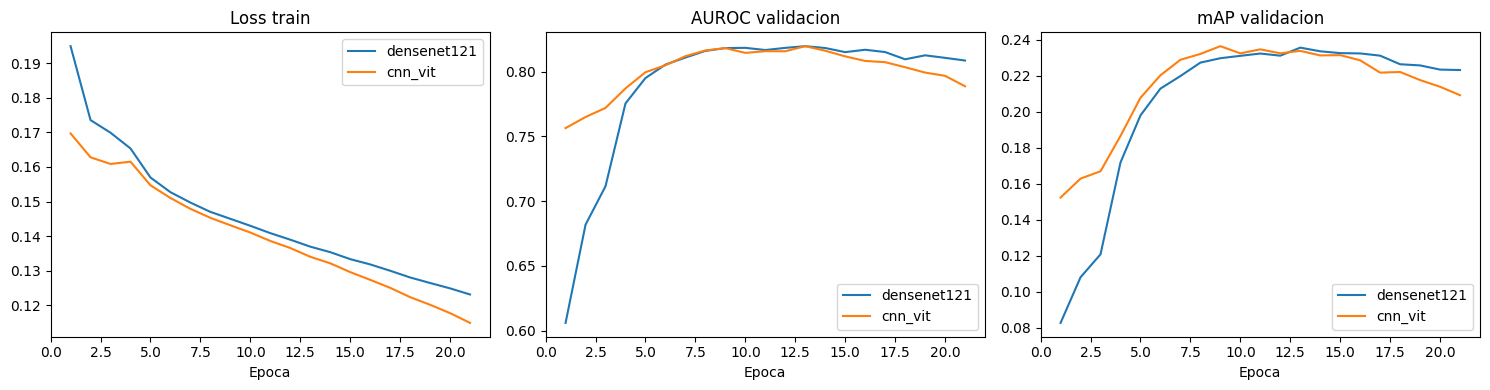

,modelo,semilla,mejor_epoca,AUROC_validacion,mAP_validacion
0,densenet121,123,13,0.819690,0.235629
1,cnn_vit,123,13,0.819678,0.233837


Esta tabla usa validacion. El test todavia no se ejecuto en este paquete.


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for architecture in ('densenet121', 'cnn_vit'):
    folder = EXPERIMENT_ROOT / architecture
    if (folder / 'training_summary.json').exists():
        summary = json.loads((folder / 'training_summary.json').read_text())
        rows.append({'modelo': architecture, 'semilla': SEED, 'mejor_epoca': summary['best_epoch'],
                     'AUROC_validacion': summary['validation']['auc_macro'], 'mAP_validacion': summary['validation']['map']})
    if (folder / 'history.json').exists():
        history = json.loads((folder / 'history.json').read_text())
        epochs = [r['epoch'] for r in history]
        axes[0].plot(epochs, [r['train_loss'] for r in history], label=architecture)
        axes[1].plot(epochs, [r['validation']['auc_macro'] for r in history], label=architecture)
        axes[2].plot(epochs, [r['validation']['map'] for r in history], label=architecture)
for axis, title in zip(axes, ('Loss train', 'AUROC validacion', 'mAP validacion')):
    axis.set_title(title)
    axis.set_xlabel('Epoca')
    if axis.lines: axis.legend()
plt.tight_layout()
plt.show()
table = pd.DataFrame(rows)
display(table)
if rows:
    table.to_csv(EXPERIMENT_ROOT / 'validation_comparison.csv', index=False)
print('Esta tabla usa validacion. El test todavia no se ejecuto en este paquete.')


## Evaluacion final: paso posterior
Mantener `RUN_FINAL_TEST = False` mientras se seleccionan configuraciones con validacion. Activarlo solo despues de fijar los modelos y umbrales. Evaluar los dos modelos usando los mismos argumentos de su entrenamiento.

El test de esta particion ya se inspecciono en el experimento anterior desde cero: los reportes registran esa limitacion. No es una cohorte externa ni una prueba confirmatoria nueva.

In [22]:
RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    subprocess.run([sys.executable, '-u', str(WORKDIR / 'train_comparison.py'), 'evaluate', *COMMON_ARGS], cwd=WORKDIR, check=True)
else:
    print('Evaluacion de test desactivada. Sigue revisando la comparacion de validacion.')


In [23]:
baseline = EXPERIMENT_ROOT / 'densenet121'
candidate = EXPERIMENT_ROOT / 'cnn_vit'
comparison = EXPERIMENT_ROOT / 'paired_comparison.json'
if RUN_FINAL_TEST and all((f / 'test_report.json').exists() for f in (baseline, candidate)):
    if not comparison.exists():
        subprocess.run([sys.executable, '-u', str(WORKDIR / 'compare_results.py'), '--baseline', str(baseline),
                        '--candidate', str(candidate), '--output', str(comparison), '--replicates', '500'], cwd=WORKDIR, check=True)
    result = json.loads(comparison.read_text())
    print('Diferencia AUROC (CNN-ViT menos CNN):', result['auc_macro_delta'])
    print('IC 95% de la diferencia:', result['auc_macro_delta_95ci'])
    print('Diferencia mAP:', result['map_delta'])
else:
    print('La comparacion emparejada se habilita despues de evaluar ambos modelos finales.')


Diferencia AUROC (CNN-ViT menos CNN): -0.0033587466243020065
IC 95% de la diferencia: [-0.008162549072007893, 0.0026997050615180057]
Diferencia mAP: -0.0017303231767243766
